<a href="https://colab.research.google.com/github/vasuyadavap-web/DATA-HANDLING/blob/main/Capstone_Project_Data_Handling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Import libraries and create the Dataset

In [2]:
# Install Plotly (run if not already installed)
!pip install plotly -q

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

from plotly.subplots import make_subplots
from IPython.display import display

# Create a 24-patient healthcare dataset
data = {
    "Age": [
        24, 31, 45, 58, 64, 29,
        52, 68, 36, 48, 61, 70,
        27, 42, 55, 66, 34, 49,
        63, 72, 26, 39, 54, 60
    ],

    "Blood_Pressure": [
        112, 118, 128, 142, 148, 115,
        136, 154, 122, 132, 146, 158,
        114, 126, 138, 150, 120, 134,
        145, 160, 116, 124, 140, 144
    ],

    "Heart_Rate": [
        68, 72, 76, 82, 85, 70,
        78, 88, 74, 77, 84, 90,
        69, 75, 80, 86, 73, 79,
        83, 92, 71, 74, 81, 84
    ],

    "Gender": [
        "Male", "Female", "Male", "Female", "Male", "Female",
        "Male", "Female", "Male", "Female", "Male", "Female",
        "Female", "Male", "Female", "Male", "Female", "Male",
        "Female", "Male", "Male", "Female", "Male", "Female"
    ],

    "Appointment_Date": pd.to_datetime([
        "2026-01-01", "2026-01-02", "2026-01-03", "2026-01-04", "2026-01-05", "2026-01-06",
        "2026-01-07", "2026-01-08", "2026-01-09", "2026-01-10", "2026-01-11", "2026-01-12",
        "2026-01-13", "2026-01-14", "2026-01-15", "2026-01-16", "2026-01-17", "2026-01-18",
        "2026-01-19", "2026-01-20", "2026-01-21", "2026-01-22", "2026-01-23", "2026-01-24"
    ])
}

df = pd.DataFrame(data)

# Display raw dataset
display(df)

,Age,Blood_Pressure,Heart_Rate,Gender,Appointment_Date
0,24,112,68,Male,2026-01-01
1,31,118,72,Female,2026-01-02
2,45,128,76,Male,2026-01-03
3,58,142,82,Female,2026-01-04
4,64,148,85,Male,2026-01-05
5,29,115,70,Female,2026-01-06
6,52,136,78,Male,2026-01-07
7,68,154,88,Female,2026-01-08
8,36,122,74,Male,2026-01-09
9,48,132,77,Female,2026-01-10


2. Explore and inspect the dataset

In [3]:
# 1. Check number of rows and columns
print("Dataset Shape:")
print(df.shape)

# 2. Check column names and data types
print("\nDataset Information:")
df.info()

# 3. Statistical summary of numerical columns
print("\nDescriptive Statistics:")
display(df.describe())

# 4. Frequency distribution of categorical column
print("\nGender-wise Patient Count:")
print(df["Gender"].value_counts())

Dataset Shape:
(24, 5)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Age               24 non-null     int64         
 1   Blood_Pressure    24 non-null     int64         
 2   Heart_Rate        24 non-null     int64         
 3   Gender            24 non-null     object        
 4   Appointment_Date  24 non-null     datetime64[ns]
dtypes: datetime64[ns](1), int64(3), object(1)
memory usage: 1.1+ KB

Descriptive Statistics:


,Age,Blood_Pressure,Heart_Rate,Appointment_Date
count,24.000000,24.000000,24.000000,24
mean,48.875000,134.250000,78.791667,2026-01-12 12:00:00
min,24.000000,112.000000,68.000000,2026-01-01 00:00:00
25%,35.500000,121.500000,73.750000,2026-01-06 18:00:00
50%,50.500000,135.000000,78.500000,2026-01-12 12:00:00
75%,61.500000,145.250000,84.000000,2026-01-18 06:00:00
max,72.000000,160.000000,92.000000,2026-01-24 00:00:00
std,15.292261,14.679918,6.807791,NaN



Gender-wise Patient Count:
Gender
Male      12
Female    12
Name: count, dtype: int64


3. Perform correlation analysis

Correlation Matrix:


,Age,Blood_Pressure,Heart_Rate
Age,1.000000,0.992543,0.982428
Blood_Pressure,0.992543,1.000000,0.995510
Heart_Rate,0.982428,0.995510,1.000000


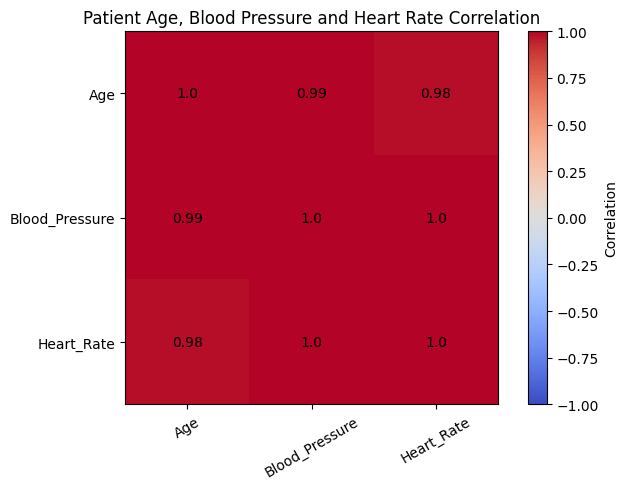

In [4]:
# Calculate correlation
correlation = df[
    ["Age", "Blood_Pressure", "Heart_Rate"]
].corr()

print("Correlation Matrix:")
display(correlation)

# Visualize correlation using a heatmap
plt.figure(figsize=(7, 5))

plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(label="Correlation")

plt.xticks(range(len(correlation.columns)),
           correlation.columns, rotation=30)

plt.yticks(range(len(correlation.columns)),
           correlation.columns)

# Display correlation values
for i in range(len(correlation.columns)):
    for j in range(len(correlation.columns)):
        plt.text(j, i, round(correlation.iloc[i, j], 2),
                 ha="center", va="center")

plt.title("Patient Age, Blood Pressure and Heart Rate Correlation")
plt.tight_layout()
plt.show()

4. Perform groupby analysis

In [5]:
# Group patients by gender
gender_summary = df.groupby("Gender").agg(
    Average_Age=("Age", "mean"),
    Average_Blood_Pressure=("Blood_Pressure", "mean"),
    Average_Heart_Rate=("Heart_Rate", "mean"),
    Patient_Count=("Age", "count")
).round(2)

print("Gender-wise Health Summary:")
display(gender_summary)

Gender-wise Health Summary:


,Average_Age,Average_Blood_Pressure,Average_Heart_Rate,Patient_Count
Gender,,,,
Female,48.50,133.67,78.50,12
Male,49.25,134.83,79.08,12


5. Create an interactive dashboard using Plotly

In [6]:
# Calculate gender-wise average blood pressure
gender_bp = df.groupby("Gender")["Blood_Pressure"].mean().reset_index()

# Create a 2x2 dashboard
fig = make_subplots(
    rows=2,
    cols=2,

    subplot_titles=(
        "Higher Patient Age Is Positively Associated with Blood Pressure",
        "Average Blood Pressure Across Gender Groups",
        "Patient Blood Pressure Spans Normal to Elevated Ranges",
        "Blood Pressure Readings Across Appointment Dates"
    ),

    specs=[
        [{"type": "xy"}, {"type": "xy"}],
        [{"type": "xy"}, {"type": "xy"}]
    ],

    vertical_spacing=0.16,
    horizontal_spacing=0.12
)

# CHART 1: Scatter plot (Top-left)
fig.add_trace(
    go.Scatter(
        x=df["Age"],
        y=df["Blood_Pressure"],
        mode="markers",
        text=df["Gender"],
        marker=dict(
            size=12,
            color=df["Heart_Rate"],
            colorscale="Viridis",
            showscale=True,
            colorbar=dict(title="Heart Rate (bpm)")
        ),
        name="Patients",
        customdata=df[["Heart_Rate", "Gender"]],
        hovertemplate=
        "<b>%{text} Patient</b><br>" +
        "Age: %{x}<br>" +
        "Blood Pressure: %{y} mmHg<br>" +
        "Heart Rate: %{customdata[0]} bpm<br>" +
        "Gender: %{customdata[1]}<extra></extra>"
    ),
    row=1, col=1
)

# CHART 2: Bar chart (Top-right)
fig.add_trace(
    go.Bar(
        x=gender_bp["Gender"],
        y=gender_bp["Blood_Pressure"],
        text=gender_bp["Blood_Pressure"].round(1),
        textposition="outside",
        name="Average Blood Pressure",
        hovertemplate=
        "Gender: %{x}<br>" +
        "Average Blood Pressure: %{y:.2f} mmHg<extra></extra>"
    ),
    row=1, col=2
)

# CHART 3: Histogram (Bottom-left)
fig.add_trace(
    go.Histogram(
        x=df["Blood_Pressure"],
        nbinsx=5,
        name="Blood Pressure Distribution",
        hovertemplate=
        "Blood Pressure Range: %{x}<br>" +
        "Number of Patients: %{y}<extra></extra>"
    ),
    row=2, col=1
)

# CHART 4: Line chart (Bottom-right)
date_summary = df.sort_values("Appointment_Date")

fig.add_trace(
    go.Scatter(
        x=date_summary["Appointment_Date"],
        y=date_summary["Blood_Pressure"],
        mode="lines+markers",
        name="Appointment Blood Pressure",
        marker=dict(size=9),
        hovertemplate=
        "Date: %{x|%d %b %Y}<br>" +
        "Blood Pressure: %{y} mmHg<extra></extra>"
    ),
    row=2, col=2
)

# Axis labels
fig.update_xaxes(title_text="Age (Years)", row=1, col=1)
fig.update_yaxes(title_text="Blood Pressure (mmHg)", row=1, col=1)

fig.update_xaxes(title_text="Gender", row=1, col=2)
fig.update_yaxes(title_text="Average Blood Pressure (mmHg)", row=1, col=2)

fig.update_xaxes(title_text="Blood Pressure (mmHg)", row=2, col=1)
fig.update_yaxes(title_text="Number of Patients", row=2, col=1)

fig.update_xaxes(title_text="Appointment Date", row=2, col=2)
fig.update_yaxes(title_text="Blood Pressure (mmHg)", row=2, col=2)

# Dashboard title and layout
fig.update_layout(
    title=dict(
        text="HEALTHCARE AND PATIENT DATA ANALYTICS DASHBOARD",
        x=0.5,
        font=dict(size=22)
    ),
    height=850,
    width=1200,
    template="plotly_white",
    showlegend=True,
    hovermode="closest"
)

# Display interactive dashboard
fig.show()

6. Export the interactive dashboard

In [7]:
# Export complete dashboard
fig.write_html(
    "Healthcare_Patient_Dashboard.html",
    include_plotlyjs=True
)

print("Dashboard exported successfully!")

Dashboard exported successfully!


To download the HTML file in Google Colab:

In [8]:
from google.colab import files
files.download("Healthcare_Patient_Dashboard.html")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

7. Dashboard Reflection

    The Healthcare and Patient Data Analytics Dashboard presents an overview of 24 patients based on their Age, Blood Pressure, Heart Rate, Gender, and Appointment Date. The scatter plot helps examine the strong positive relationship between patient age, blood pressure, and heart rate, while the bar chart compares average blood pressure levels between Male and Female patients. The histogram shows the frequency distribution of blood pressure readings across normal and elevated ranges, and the line chart presents blood pressure measurements in chronological appointment-date order. The correlation matrix and groupby analysis provide additional numerical insights, showing that older patients consistently exhibit higher blood pressure and heart rate values while average readings remain closely balanced across genders. Overall, the dashboard helps identify important patient health patterns in the dataset, though observations from 24 records should not be generalized to a larger clinical population without further data.